# 05 - Entraînement du modèle

Entraînement et sauvegarde du modèle de churn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import sklearn
import streamlit as st
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
#from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import joblib
from sklearn.metrics import ( ConfusionMatrixDisplay, accuracy_score, make_scorer, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report,ConfusionMatrixDisplay,make_scorer,auc, roc_curve)
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


print("Toutes les bibliothèques sont installées.")

Toutes les bibliothèques sont installées.


In [2]:
# Affichage de toutes les colonnes du dataset
df = pd.read_csv('D:\\IBM\\data\\IBM-Telco-Customer-Churn_cleaned.csv')
print(df.columns.tolist())

# Affichage des dimensions
print("Dimensions :", df.shape)

# Vérification des types de données
print(df.dtypes)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Dimensions : (7043, 20)
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [3]:
#préparation de X et y
X = df.drop('Churn', axis=1)
y = df['Churn']
print("Dimension de X:", X.shape)
print("Dimension de y:", y.shape)

Dimension de X: (7043, 19)
Dimension de y: (7043,)


In [4]:
#Separation des données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Dimension de X_train:", X_train.shape)
print("Dimension de X_test:", X_test.shape)
print("Dimension de y_train:", y_train.shape)
print("Dimension de y_test:", y_test.shape)


Dimension de X_train: (5634, 19)
Dimension de X_test: (1409, 19)
Dimension de y_train: (5634,)
Dimension de y_test: (1409,)


In [5]:
print("Répartition initiale :")
print(y.value_counts(normalize=True) * 100)

print("\nRépartition Train :")
print(y_train.value_counts(normalize=True) * 100)

print("\nRépartition Test :")
print(y_test.value_counts(normalize=True) * 100)

Répartition initiale :
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Répartition Train :
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Répartition Test :
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [6]:

# Variables numériques
numerical_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Variables catégorielles
categorical_columns = [
    column for column in X_train.columns
    if column not in numerical_columns
]

print("Variables numériques :")
print(numerical_columns)

print("\nVariables catégorielles :")
print(categorical_columns)

print("\nNombre de variables numériques :", len(numerical_columns))
print("Nombre de variables catégorielles :", len(categorical_columns))


Variables numériques :
['tenure', 'MonthlyCharges', 'TotalCharges']

Variables catégorielles :
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Nombre de variables numériques : 3
Nombre de variables catégorielles : 16


In [7]:

print("Valeurs manquantes dans X_train :")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nValeurs manquantes dans X_test :")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])


Valeurs manquantes dans X_train :
TotalCharges    8
dtype: int64

Valeurs manquantes dans X_test :
TotalCharges    3
dtype: int64


In [8]:

# 1. Pipeline des variables numériques
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Pipeline des variables catégorielles
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 3. Préprocesseur global
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_columns),
    ('cat', categorical_transformer, categorical_columns)
])

print("Préprocesseur créé avec succès !")


Préprocesseur créé avec succès !


In [9]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
            

In [10]:
#Transformation des données
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print("Dimension de X_train_transformed:", X_train_transformed.shape)
print("Dimension de X_test_transformed:", X_test_transformed.shape)
print("Transformation des données terminée avec succès !")

Dimension de X_train_transformed: (5634, 46)
Dimension de X_test_transformed: (1409, 46)
Transformation des données terminée avec succès !


In [11]:
#Vérification des dimensions après transformation
print("Dimension de X_train_transformed:", X_train_transformed.shape)
print("Dimension de X_test_transformed:", X_test_transformed.shape)


Dimension de X_train_transformed: (5634, 46)
Dimension de X_test_transformed: (1409, 46)


In [12]:
# Vérification des valeurs manquantes
print("Valeurs manquantes dans X_train_transformed :")
print(np.isnan(X_train_transformed).sum())

print("\nValeurs manquantes dans X_test_transformed :")
print(np.isnan(X_test_transformed).sum())


Valeurs manquantes dans X_train_transformed :
0

Valeurs manquantes dans X_test_transformed :
0


In [13]:
print("Dimensions avant transformation :")
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("\nDimensions après transformation :")
print("X_train_transformed :", X_train_transformed.shape)
print("X_test_transformed :", X_test_transformed.shape)

Dimensions avant transformation :
X_train : (5634, 19)
X_test : (1409, 19)

Dimensions après transformation :
X_train_transformed : (5634, 46)
X_test_transformed : (1409, 46)


In [14]:
print(type(X_train_transformed))
print(type(X_test_transformed))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [15]:
##Créer et entraîner le modèle
#  Initialisation du modèle
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Entraînement
logistic_model.fit(X_train_transformed, y_train)

print("Entraînement terminé avec succès !")

Entraînement terminé avec succès !


In [16]:
##Effectuer les prédictions
# Prédictions sur les données de test
y_pred = logistic_model.predict(X_test_transformed)

# Probabilités de résiliation
y_proba = logistic_model.predict_proba(X_test_transformed)[:, 1]

print("Premières prédictions :")
print(y_pred[:10])

print("\nProbabilités de résiliation :")
print(y_proba[:10])

Premières prédictions :
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Probabilités de résiliation :
[0.04535847 0.68360771 0.0591177  0.40133964 0.0216345  0.60328007
 0.44814103 0.1309129  0.00293725 0.3950712 ]


In [17]:
print(logistic_model.classes_)

['No' 'Yes']


In [18]:
#Le message de confirmation de l'entraînement.
print("Le modèle a été entraîné avec succès !")

#Les dix premières prédictions.
print("Dix premières prédictions :")
print(y_pred[:10])

#Les dix premières probabilités
print("Dix premières probabilités :")
print(y_proba[:10])

Le modèle a été entraîné avec succès !
Dix premières prédictions :
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']
Dix premières probabilités :
[0.04535847 0.68360771 0.0591177  0.40133964 0.0216345  0.60328007
 0.44814103 0.1309129  0.00293725 0.3950712 ]


In [19]:
#évaluation du modèle

# Calcul des métriques
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='Yes')
recall = recall_score(y_test, y_pred, pos_label='Yes')
f1 = f1_score(y_test, y_pred, pos_label='Yes')

# Récupérer la colonne de probabilité correspondant à Yes
yes_index = list(logistic_model.classes_).index('Yes')
y_proba_yes = logistic_model.predict_proba(X_test_transformed)[:, yes_index]

roc_auc = roc_auc_score(
    (y_test == 'Yes').astype(int),
    y_proba_yes
)

# Affichage
print("ÉVALUATION DU MODÈLE : RÉGRESSION LOGISTIQUE")
print("-" * 45)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))


ÉVALUATION DU MODÈLE : RÉGRESSION LOGISTIQUE
---------------------------------------------
Accuracy  : 0.8055
Precision : 0.6572
Recall    : 0.5588
F1-score  : 0.6040
ROC-AUC   : 0.8419

Rapport de classification :
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



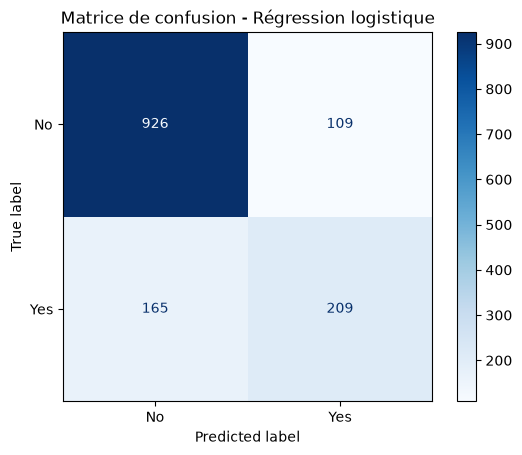

In [20]:
#Construction de la matrice de confusion


cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

display.plot(cmap='Blues')
plt.title("Matrice de confusion - Régression logistique")
plt.show()

In [21]:
#Vérification des erreurs du modèle

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

print(cm)

[[926 109]
 [165 209]]


In [22]:
#amélioration du Recall
y_pred_proba = logistic_model.predict_proba(X_test_transformed)

In [23]:
#Création d'un ensemble de validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
print("Dimension des ensembles :")
print("X_train :", X_train.shape)
print("X_val :", X_val.shape)
print("y_train :", y_train.shape)
print("y_val :", y_val.shape)

Dimension des ensembles :
X_train : (4507, 19)
X_val : (1127, 19)
y_train : (4507,)
y_val : (1127,)


In [24]:

print("X_train :", X_train.shape)
print("X_val :", X_val.shape)
print("y_train :", y_train.shape)
print("y_val :", y_val.shape)

X_train : (4507, 19)
X_val : (1127, 19)
y_train : (4507,)
y_val : (1127,)


In [25]:
# Apprentissage du préprocesseur sur le nouvel ensemble Train
X_train_sub_transformed = preprocessor.fit_transform(X_train)

# Transformation de la validation
X_val_transformed = preprocessor.transform(X_val)

print("Dimensions après transformation :")
print("Train :", X_train_sub_transformed.shape)
print("Validation :", X_val_transformed.shape)

Dimensions après transformation :
Train : (4507, 46)
Validation : (1127, 46)


In [26]:
#Entraîner le modèle sur Train

# Initialisation du modèle
logistic_model_val = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Entraînement
logistic_model_val.fit(
    X_train_sub_transformed,
    y_train
)

print("Modèle entraîné avec succès !")

Modèle entraîné avec succès !


In [27]:
#Calcule des probabilités sur Validation
# Identifier la position de la classe Yes
yes_index = list(logistic_model_val.classes_).index('Yes')

# Calculer les probabilités
y_val_proba = logistic_model_val.predict_proba(
    X_val_transformed
)[:, yes_index]

print("Premières probabilités :")
print(y_val_proba[:10])

Premières probabilités :
[0.19593159 0.01868098 0.05282058 0.16559049 0.25417595 0.03567068
 0.17851089 0.01420082 0.01529788 0.24580315]


In [28]:
#Comparaison des seuils


from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Seuils à comparer
thresholds = [0.50, 0.45, 0.40, 0.35, 0.30]

results = []

for threshold in thresholds:

    # Transformer les probabilités en prédictions
    y_val_pred = [
        'Yes' if proba >= threshold else 'No'
        for proba in y_val_proba
    ]

    # Calculer les métriques
    precision = precision_score(
        y_val, y_val_pred, pos_label='Yes'
    )

    recall = recall_score(
        y_val, y_val_pred, pos_label='Yes'
    )

    f1 = f1_score(
        y_val, y_val_pred, pos_label='Yes'
    )

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    })

# Créer le tableau comparatif
threshold_results = pd.DataFrame(results)

print(threshold_results.round(4))


   Threshold  Precision  Recall  F1-score
0       0.50     0.6966  0.5452    0.6116
1       0.45     0.6606  0.6054    0.6318
2       0.40     0.6204  0.6722    0.6453
3       0.35     0.5792  0.7090    0.6376
4       0.30     0.5433  0.7559    0.6322


In [29]:
#Réentraînement du préprocesseur et du modèle
# Réapprentissage du préprocesseur sur tout X_train
X_train_final = preprocessor.fit_transform(X_train)

# Transformation du jeu de test
X_test_final = preprocessor.transform(X_test)

# Création du modèle final
logistic_model_final = LogisticRegression(max_iter=1000, random_state=42)

# Entraînement
logistic_model_final.fit(X_train_final, y_train)

print("Modèle final entraîné avec succès !")

Modèle final entraîné avec succès !


In [30]:
#Prédictions avec le seuil de 0,40

# Position de la classe Yes
yes_index = list(logistic_model_final.classes_).index('Yes')

# Probabilités de résiliation
y_test_proba = logistic_model_final.predict_proba(X_test_final)[:, yes_index]

# Application du seuil sélectionné
y_test_pred_040 = np.where(
    y_test_proba >= 0.40,
    'Yes',
    'No'
)

print("Premières prédictions :")
print(y_test_pred_040[:10])

Premières prédictions :
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'Yes' 'No' 'No' 'No']


In [31]:
#Évaluer les performances finales
print("ÉVALUATION FINALE - SEUIL 0.40")
print("-" * 40)

print(f"Accuracy  : {accuracy_score(y_test, y_test_pred_040):.4f}")
print(f"Precision : {precision_score(y_test, y_test_pred_040, pos_label='Yes'):.4f}")
print(f"Recall    : {recall_score(y_test, y_test_pred_040, pos_label='Yes'):.4f}")
print(f"F1-score  : {f1_score(y_test, y_test_pred_040, pos_label='Yes'):.4f}")
print(f"ROC-AUC   : {roc_auc_score((y_test == 'Yes').astype(int), y_test_proba):.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_test_pred_040))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_test_pred_040, labels=['No', 'Yes']))

ÉVALUATION FINALE - SEUIL 0.40
----------------------------------------
Accuracy  : 0.7828
Precision : 0.5780
Recall    : 0.6738
F1-score  : 0.6222
ROC-AUC   : 0.8425

Rapport de classification :
              precision    recall  f1-score   support

          No       0.87      0.82      0.85      1035
         Yes       0.58      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.73      1409
weighted avg       0.80      0.78      0.79      1409


Matrice de confusion :
[[851 184]
 [122 252]]


In [32]:
#Définition des modèles à comparer
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

In [33]:
#Entraînement et évaluation

results = []
trained_models = {}

for name, model in models.items():

    # Créer un pipeline indépendant
    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    # Entraîner sur Train
    pipeline.fit(X_train, y_train)

    # Prédictions sur Validation
    y_pred_val = pipeline.predict(X_val)

    # Probabilités de la classe Yes
    yes_index = list(pipeline.classes_).index('Yes')

    y_proba_val = pipeline.predict_proba(X_val)[:, yes_index]

    # Calcul des métriques
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_pred_val),
        'Precision': precision_score(
            y_val, y_pred_val, pos_label='Yes'
        ),
        'Recall': recall_score(
            y_val, y_pred_val, pos_label='Yes'
        ),
        'F1-score': f1_score(
            y_val, y_pred_val, pos_label='Yes'
        ),
        'ROC-AUC': roc_auc_score(
            (y_val == 'Yes').astype(int),
            y_proba_val
        )
    })

    trained_models[name] = pipeline

# Tableau comparatif
comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0  Logistic Regression    0.8163     0.6966  0.5452    0.6116   0.8481
1        Random Forest    0.7746     0.5664  0.6421    0.6019   0.8222
2    Gradient Boosting    0.8066     0.6938  0.4849    0.5709   0.8495


In [34]:

thresholds = np.arange(0.30, 0.61, 0.05)

threshold_results = []

for model_name, model in trained_models.items():

    yes_index = list(model.classes_).index('Yes')

    y_proba = model.predict_proba(X_val)[:, yes_index]

    for threshold in thresholds:

        y_pred = np.where(
            y_proba >= threshold,
            'Yes',
            'No'
        )

        threshold_results.append({
            'Model': model_name,
            'Threshold': round(threshold, 2),
            'Precision': precision_score(
                y_val, y_pred, pos_label='Yes'
            ),
            'Recall': recall_score(
                y_val, y_pred, pos_label='Yes'
            ),
            'F1-score': f1_score(
                y_val, y_pred, pos_label='Yes'
            )
        })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

              Model  Threshold  Precision  Recall  F1-score
Logistic Regression       0.30     0.5433  0.7559    0.6322
Logistic Regression       0.35     0.5792  0.7090    0.6376
Logistic Regression       0.40     0.6204  0.6722    0.6453
Logistic Regression       0.45     0.6606  0.6054    0.6318
Logistic Regression       0.50     0.6966  0.5452    0.6116
Logistic Regression       0.55     0.7353  0.5017    0.5964
Logistic Regression       0.60     0.7303  0.3712    0.4922
      Random Forest       0.30     0.4583  0.8261    0.5895
      Random Forest       0.35     0.4855  0.7826    0.5992
      Random Forest       0.40     0.5068  0.7458    0.6035
      Random Forest       0.45     0.5193  0.6756    0.5872
      Random Forest       0.50     0.5673  0.6488    0.6053
      Random Forest       0.55     0.5960  0.5920    0.5940
      Random Forest       0.60     0.6148  0.5017    0.5525
  Gradient Boosting       0.30     0.5459  0.7559    0.6339
  Gradient Boosting       0.35     0.586

In [35]:
#optimisation Gradient Boosting


# Pipeline complet
gb_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# Hyperparamètres à tester
param_distributions = {
    'classifier__n_estimators': [100, 150, 200, 250, 300],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'classifier__max_depth': [2, 3, 4, 5],
    'classifier__min_samples_split': [2, 5, 10, 15],
    'classifier__min_samples_leaf': [1, 2, 4, 6],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0]
}

# Validation croisée
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Optimisation
random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring=make_scorer(f1_score, pos_label='Yes'),
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Entraînement
random_search.fit(X_train, y_train)

# Résultats
print("Meilleurs paramètres :")
print(random_search.best_params_)

print("\nMeilleur F1-score en validation croisée :")
print(round(random_search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Meilleurs paramètres :
{'classifier__subsample': 0.8, 'classifier__n_estimators': 150, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.03}

Meilleur F1-score en validation croisée :
0.5749


In [36]:
#Évaluation du modèle optimisé sur X_val

# Récupérer le meilleur modèle
best_gb_model = random_search.best_estimator_

# Prédictions sur validation
y_val_pred = best_gb_model.predict(X_val)

# Probabilités de prédiction
yes_index = list(best_gb_model.classes_).index('Yes')

y_val_proba = best_gb_model.predict_proba(X_val)[:, yes_index]

# Métriques au seuil de 0.5
print("Accuracy :", round(accuracy_score(y_val, y_val_pred), 4))

print("Precision :", round(
    precision_score(y_val, y_val_pred, pos_label='Yes'), 4
))

print("Recall :", round(
    recall_score(y_val, y_val_pred, pos_label='Yes'), 4
))

print("F1-score :", round(
    f1_score(y_val, y_val_pred, pos_label='Yes'), 4
))

print("ROC-AUC :", round(
    roc_auc_score((y_val == 'Yes').astype(int), y_val_proba), 4
))

print("\nClassification Report :")
print(classification_report(y_val, y_val_pred))

Accuracy : 0.8154
Precision : 0.7116
Recall : 0.5117
F1-score : 0.5953
ROC-AUC : 0.8527

Classification Report :
              precision    recall  f1-score   support

          No       0.84      0.93      0.88       828
         Yes       0.71      0.51      0.60       299

    accuracy                           0.82      1127
   macro avg       0.78      0.72      0.74      1127
weighted avg       0.81      0.82      0.80      1127



In [37]:
#Optimisation du seuil du Gradient Boosting

thresholds = np.arange(0.25, 0.61, 0.05)

optimized_gb_results = []

for threshold in thresholds:

    y_pred = np.where(y_val_proba >= threshold, 'Yes', 'No')

    optimized_gb_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(
            y_val, y_pred, pos_label='Yes'
        ),
        'Recall': recall_score(
            y_val, y_pred, pos_label='Yes'
        ),
        'F1-score': f1_score(
            y_val, y_pred, pos_label='Yes'
        )
    })

optimized_gb_df = pd.DataFrame(optimized_gb_results)

print(optimized_gb_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.25     0.5064  0.7926    0.6180
      0.30     0.5572  0.7659    0.6451
      0.35     0.5994  0.7258    0.6566
      0.40     0.6467  0.6488    0.6477
      0.45     0.6883  0.5686    0.6227
      0.50     0.7116  0.5117    0.5953
      0.55     0.7321  0.4114    0.5268
      0.60     0.7372  0.3378    0.4633


Interprétation métier
Avec ce modèle :
- Recall de 72,58 % : il détecte environ 73 clients sur 100 qui vont réellement résilier.
- Precision de 59,94 % : parmi les clients signalés comme susceptibles de résilier, environ 60 % résilient effectivement.
- F1-score de 65,66 % : compromis entre précision et détection.
Pour une entreprise télécom, ce modèle pourrait aider à identifier les clients à contacter en priorité pour des actions de fidélisation.

In [38]:
#Décision provisoire
best_threshold = 0.35
best_model = best_gb_model
best_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

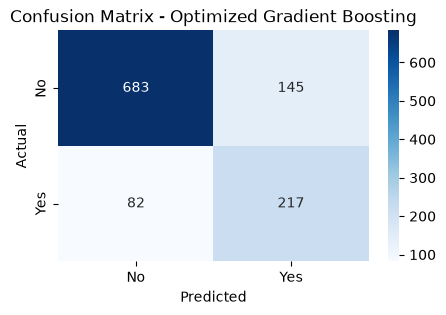

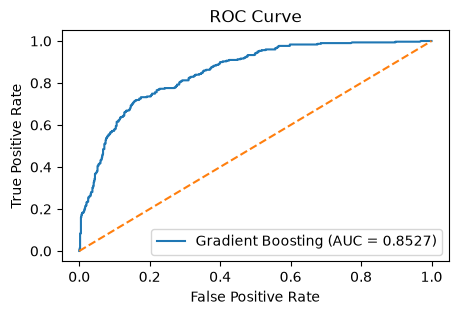

In [39]:

# Prédictions avec le seuil retenu

y_val_pred_035 = np.where(y_val_proba >= 0.35, 'Yes', 'No')

# Matrice de confusion
cm = confusion_matrix( y_val, y_val_pred_035, labels = ['No', 'Yes'])

plt.figure(figsize=(5, 3))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels = ['No', 'Yes'], yticklabels = ['No', 'Yes'])

plt.title('Confusion Matrix - Optimized Gradient Boosting')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Courbe ROC
y_val_binary = (y_val == 'Yes').astype(int)

fpr, tpr, thresholds_roc = roc_curve(y_val_binary, y_val_proba)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5, 3))

plt.plot(fpr,tpr,label=f'Gradient Boosting (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [40]:

y_val_pred_final = np.where(y_val_proba >= 0.35, 'Yes', 'No')

cm = confusion_matrix(y_val, y_val_pred_final, labels=['No', 'Yes'])
cm

array([[683, 145],
       [ 82, 217]])

In [41]:

#récupération des données d'entraînement complètes

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Entraînement :", X_train_full.shape)
print("Test :", X_test.shape)

Entraînement : (5634, 19)
Test : (1409, 19)


In [42]:
# Création du pipeline final
final_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', GradientBoostingClassifier(
        subsample=0.8,
        n_estimators=150,
        min_samples_split=2,
        min_samples_leaf=2,
        max_depth=3,
        learning_rate=0.03,
        random_state=42
    ))
])

# Entraînement sur les 80 % de données
final_model.fit(X_train_full, y_train_full)

print("Entraînement du modèle final terminé !")

Entraînement du modèle final terminé !


In [43]:
#évaluation du modèle final

# Probabilités de prédiction
yes_index = list(final_model.classes_).index('Yes')

y_test_proba = final_model.predict_proba(X_test)[:, yes_index]

# Application du seuil de 0.35
y_test_pred = np.where(y_test_proba >= 0.35, 'Yes', 'No')

# Calcul des métriques
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("Precision :", precision_score(y_test, y_test_pred, pos_label='Yes'))
print("Recall :", recall_score(y_test, y_test_pred, pos_label='Yes'))
print("F1-score :", f1_score(y_test, y_test_pred, pos_label='Yes'))
print("ROC-AUC :", roc_auc_score((y_test == 'Yes').astype(int), y_test_proba))

print("\nRapport de classification :")
print(classification_report(y_test, y_test_pred))

print("Matrice de confusion :")
confusion_matrix(y_test, y_test_pred, labels=['No', 'Yes'])

Accuracy : 0.7842441447835344
Precision : 0.5760869565217391
Recall : 0.7085561497326203
F1-score : 0.6354916067146283
ROC-AUC : 0.8461895166498747

Rapport de classification :
              precision    recall  f1-score   support

          No       0.89      0.81      0.85      1035
         Yes       0.58      0.71      0.64       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.78      0.79      1409

Matrice de confusion :


array([[840, 195],
       [109, 265]])

In [44]:
# Création du dossier models
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder le pipeline
joblib.dump(final_model, models_dir / "churn_model.pkl")

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !


In [45]:
test_dir = Path("../data/processed")
test_dir.mkdir(parents=True, exist_ok=True)

X_test.to_csv(test_dir / "X_test.csv", index=False)
y_test.to_csv(test_dir / "y_test.csv", index=False)

print("Données de test exportées avec succès !")

Données de test exportées avec succès !
